In [2]:
#memanggil library
import pandas as pd
import matplotlib.pyplot as plt

library pandas digunakan untuk mengolah dataset dalam bentuk tabel, sedangkan matplotlib digunakan untuk membuat visualisasi grafik

In [4]:
# membaca dataset
df = pd.read_csv("paket_a_transaksi_pos_2024_2025.csv")

# menampilkan 5 baris pertama
display(df.head())

# menampilkan struktur dan tipe data
df.info()

# menampilkan jumlah baris dan kolom
print("jumlah baris dan kolom:", df.shape)

,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


<class 'pandas.DataFrame'>
RangeIndex: 5030 entries, 0 to 5029
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   id_transaksi   5030 non-null   str  
 1   tanggal        5030 non-null   str  
 2   kode_gerai     5030 non-null   str  
 3   kode_kasir     4769 non-null   str  
 4   kode_produk    5030 non-null   str  
 5   jumlah         5030 non-null   int64
 6   harga_satuan   5030 non-null   str  
 7   diskon_persen  5030 non-null   int64
 8   status         5030 non-null   str  
dtypes: int64(2), str(7)
memory usage: 578.2 KB
jumlah baris dan kolom: (5030, 9)


head() untuk menampilkan lima data pertama
info() menampilkan tipe data dan jumlah nilai terisi
shape menunjukkan ukuran dataset

Hasil dataset berisi 5.030 baris dan 9 kolom dan data ini menjadi bahan untuk seluruh proses analisis selanjutnya

In [5]:
#memeriksa missing value
# menghitung nilai kosong setiap kolom
missing = df.isnull().sum()

# menampilkan hanya kolom yang memiliki missing value
print("kolom yang memiliki missing value:")
display(missing[missing > 0])

# menghitung persentase missing value
persentase_missing = (
    df.isnull().sum() / len(df) * 100
).round(2)

display(persentase_missing[persentase_missing > 0])

kolom yang memiliki missing value:


kode_kasir    261
dtype: int64

kode_kasir    5.19
dtype: float64

kode ini mendeteksi nilai kosong atau NaN di setiap kolom. pada dataset tersebut, kolom kode_kasir memiliki 261 nilai kosong
nilai kosong perlu diperiksa karena dapat memengaruhi kelengkapan informasi transaksi

In [6]:
#menangani missing value
#membuat salinan dataset
df = df.copy()

# mengisi kode kasir kosong dengan label khusus
df["kode_kasir"] = df["kode_kasir"].fillna(
    "TIDAK DIKETAHUI"
)

# memeriksa kembali missing value
print("missing value setelah penanganan:")
display(df.isnull().sum())

missing value setelah penanganan:


id_transaksi     0
tanggal          0
kode_gerai       0
kode_kasir       0
kode_produk      0
jumlah           0
harga_satuan     0
diskon_persen    0
status           0
dtype: int64

Pada kolom kode_kasir merupakan data kategori, bukan angka untuk perhitungan. dikarenakan nilai kosong diisi dengan label "TIDAK DIKETAHUI", bukan rata-rata atau modus. dikarenakan agar mempertahankan data transaksi tanpa menebak identitas kasir

In [7]:
#membersihkan tanggal dan harga satuan
#membersihkan dan mengubah tanggal
df["tanggal"] = pd.to_datetime(
    df["tanggal"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

#membersihkan format harga
harga = (
    df["harga_satuan"]
    .astype(str)
    .str.strip()
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
)

#mengubah harga menjadi angka
df["harga_satuan"] = pd.to_numeric(
    harga,
    errors="coerce"
)

#menampilkan tipe data terbaru
df.info()

#memeriksa tanggal dan harga yang gagal dikonversi
display(
    df[["tanggal", "harga_satuan"]].isnull().sum()
)

<class 'pandas.DataFrame'>
RangeIndex: 5030 entries, 0 to 5029
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   id_transaksi   5030 non-null   str           
 1   tanggal        5030 non-null   datetime64[us]
 2   kode_gerai     5030 non-null   str           
 3   kode_kasir     5030 non-null   str           
 4   kode_produk    5030 non-null   str           
 5   jumlah         5030 non-null   int64         
 6   harga_satuan   5030 non-null   float64       
 7   diskon_persen  5030 non-null   int64         
 8   status         5030 non-null   str           
dtypes: datetime64[us](1), float64(1), int64(2), str(5)
memory usage: 508.5 KB


tanggal         0
harga_satuan    0
dtype: int64

pada tanggal di dataset memiliki format yang beragam, sedangkan harga satuan mengandung penulisan seperti 7500,00. dikarenakan kode ini menyeragamkan format tersebut agar tanggal bisa digunakan untuk mengambil tahun dan harga bisa digunakan dalam perhitungan

In [8]:
#memeriksa status transaksi
#menghitung jumlah transaksi setiap status
jumlah_status = df["status"].value_counts()

display(
    jumlah_status.rename_axis("Status")
    .reset_index(name="Jumlah Transaksi")
)

,Status,Jumlah Transaksi
0,SELESAI,4749
1,BATAL,191
2,RETUR,90


untuk dataset memiliki tiga status, yaitu SELESAI, BATAL, dan RETUR
untuk analisis pendapatan penjualan, kita akan menggunakan transaksi yang berstatus SELESAI
untuk transaksi batal tidak menghasilkan penjualan selesai
untuk retur dipisahkan karena bukan penjualan selesai biasa

In [9]:
#membersihkan data transaksi dan menghitung pendapatan bersih
#mengubah kolom jumlah dan diskon menjadi angka
df["jumlah"] = pd.to_numeric(
    df["jumlah"], errors="coerce"
)

df["diskon_persen"] = pd.to_numeric(
    df["diskon_persen"], errors="coerce"
)

#mengambil transaksi dengan status selesai
df_valid = df[
    df["status"].astype(str).str.strip().str.upper()
    == "SELESAI"
].copy()

#menghapus data yang tidak bisa dihitung
df_valid = df_valid.dropna(
    subset=[
        "tanggal",
        "jumlah",
        "harga_satuan",
        "diskon_persen"
    ]
)

#menghapus jumlah nol/negatif dan diskon di luar rentang 0-100%
df_valid = df_valid[
    (df_valid["jumlah"] > 0) &
    (df_valid["diskon_persen"].between(0, 100)) &
    (df_valid["harga_satuan"] >= 0)
].copy()

#menghitung pendapatan kotor
df_valid["pendapatan_kotor"] = (
    df_valid["jumlah"] * df_valid["harga_satuan"]
)

#menghitung pendapatan bersih setelah diskon
df_valid["pendapatan_bersih"] = (
    df_valid["pendapatan_kotor"] *
    (1 - df_valid["diskon_persen"] / 100)
)

#menampilkan hasil perhitungan
display(
    df_valid[
        [
            "id_transaksi",
            "tanggal",
            "jumlah",
            "harga_satuan",
            "diskon_persen",
            "pendapatan_kotor",
            "pendapatan_bersih"
        ]
    ].head(10)
)

print("jumlah transaksi yang dianalisis:", len(df_valid))

,id_transaksi,tanggal,jumlah,harga_satuan,diskon_persen,pendapatan_kotor,pendapatan_bersih
0,TRX0241065,2025-02-06,4,13000.0,0,52000.0,52000.0
1,TRX0240510,2024-12-28,1,21000.0,0,21000.0,21000.0
2,TRX0244483,2024-04-09,3,7500.0,0,22500.0,22500.0
3,TRX0242532,2025-07-30,2,6500.0,0,13000.0,13000.0
4,TRX0243509,2025-03-26,1,6000.0,0,6000.0,6000.0
5,TRX0240658,2025-07-18,12,45500.0,10,546000.0,491400.0
6,TRX0244581,2025-09-24,1,18000.0,0,18000.0,18000.0
7,TRX0241251,2024-09-10,4,47500.0,10,190000.0,171000.0
8,TRX0244274,2024-03-20,3,11000.0,0,33000.0,33000.0
10,TRX0243788,2024-04-19,4,33500.0,10,134000.0,120600.0


jumlah transaksi yang dianalisis: 4712


hasil pendapatan kotor dihitung dari jumlah barang dikali harga satuan. setelah itu, diskon dikurangkan berdasarkan persentase diskon pada setiap transaksi.
jadi, juga mengecualikan jumlah barang nol atau negatif karena analisis ini difokuskan pada penjualan positif yang selesai. data tersebut tidak langsung dihapus dari dataset asli, melainkan hanya dikecualikan dari df_valid

In [11]:
#menghitung pendapatan tahun 2024 dan 2025
#mengambil tahun dari tanggal transaksi
df_valid["tahun"] = df_valid["tanggal"].dt.year

#memilih transaksi tahun 2024 dan 2025
df_analisis = df_valid[
    df_valid["tahun"].isin([2024, 2025])
].copy()

#menghitung total pendapatan setiap tahun
pendapatan_tahunan = (
    df_analisis.groupby("tahun")["pendapatan_bersih"]
    .sum()
    .reindex([2024, 2025], fill_value=0)
    .reset_index()
)

#mengganti nama kolom
pendapatan_tahunan.columns = [
    "Tahun",
    "Total Pendapatan Bersih (Rp)"
]

#menampilkan tabel hasil
display(pendapatan_tahunan.round(2))

,Tahun,Total Pendapatan Bersih (Rp)
0,2024,387847925.0
1,2025,259271725.0


kode ini mengambil tahun dari kolom tanggal dan menjumlahkan pendapatan bersih setiap tahun. hasilnya berupa tabel yang menunjukkan total pendapatan 2024 dan 2025

In [12]:
#menghitung selisih dan persentase perubahan pendapatan
pendapatan_2024 = pendapatan_tahunan.loc[
    pendapatan_tahunan["Tahun"] == 2024,
    "Total Pendapatan Bersih (Rp)"
].iloc[0]

pendapatan_2025 = pendapatan_tahunan.loc[
    pendapatan_tahunan["Tahun"] == 2025,
    "Total Pendapatan Bersih (Rp)"
].iloc[0]

selisih = pendapatan_2025 - pendapatan_2024

print(f"pendapatan 2024: Rp{pendapatan_2024:,.2f}")
print(f"pendapatan 2025: Rp{pendapatan_2025:,.2f}")
print(f"selisih pendapatan: Rp{selisih:,.2f}")

if pendapatan_2024 != 0:
    perubahan = selisih / pendapatan_2024 * 100
    print(f"persentase perubahan: {perubahan:.2f}%")
else:
    print("persentase perubahan tidak dapat dihitung.")

pendapatan 2024: Rp387,847,925.00
pendapatan 2025: Rp259,271,725.00
selisih pendapatan: Rp-128,576,200.00
persentase perubahan: -33.15%


jika selisih positif, pendapatan tahun 2025 lebih tinggi
jika selisih negatif, pendapatan tahun 2025 lebih rendah
persentase perubahan menunjukkan besar kenaikan atau penurunan dibandingkan pendapatan 2024

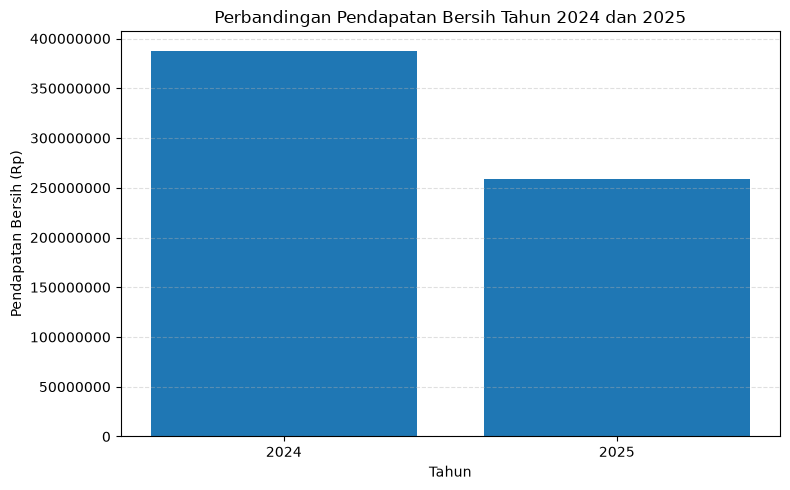

In [13]:
#grafik perbandingan pendapatan tahunan
plt.figure(figsize=(8, 5))

plt.bar(
    pendapatan_tahunan["Tahun"].astype(str),
    pendapatan_tahunan["Total Pendapatan Bersih (Rp)"]
)

plt.title("Perbandingan Pendapatan Bersih Tahun 2024 dan 2025")
plt.xlabel("Tahun")
plt.ylabel("Pendapatan Bersih (Rp)")
plt.ticklabel_format(axis="y", style="plain")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

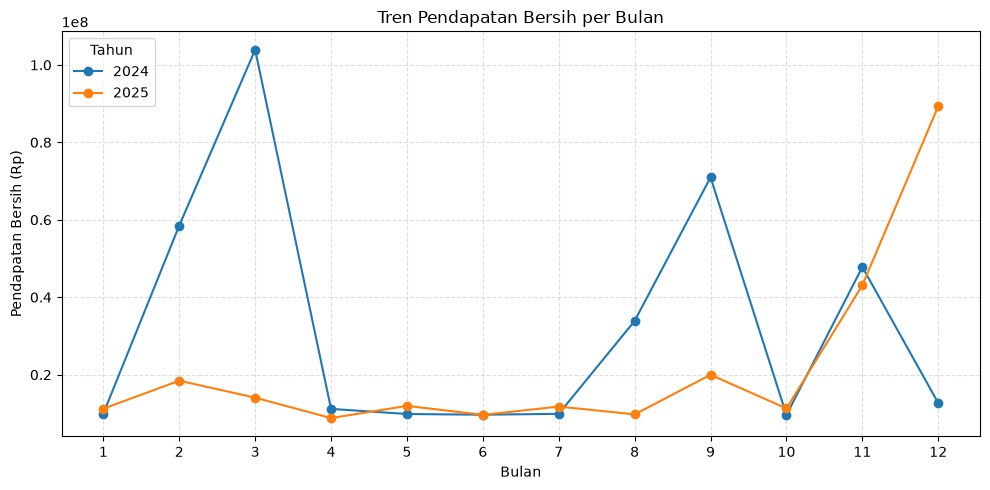

In [15]:
#grafik pendapatan per bulan
#mengambil bulan dan tahun transaksi
df_analisis["bulan"] = df_analisis["tanggal"].dt.month

# menjumlahkan pendapatan berdasarkan tahun dan bulan
pendapatan_bulanan = (
    df_analisis.groupby(["tahun", "bulan"])["pendapatan_bersih"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(10, 5))

for tahun in [2024, 2025]:
    data_tahun = pendapatan_bulanan[
        pendapatan_bulanan["tahun"] == tahun
    ]

    plt.plot(
        data_tahun["bulan"],
        data_tahun["pendapatan_bersih"],
        marker="o",
        label=str(tahun)
    )

plt.title("Tren Pendapatan Bersih per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Pendapatan Bersih (Rp)")
plt.xticks(range(1, 13))
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(title="Tahun")

plt.tight_layout()
plt.show()

untuk diagram batang memudahkan kita membandingkan pendapatan kedua tahun. batang yang lebih tinggi menunjukkan pendapatan bersih yang lebih besar
untuk grafik garis ini menunjukkan perubahan pendapatan setiap bulan. dari grafik tersebut, dapat melihat bulan dengan pendapatan tinggi, bulan dengan pendapatan rendah, dan perbedaan pola pendapatan antara 2024 dan 2025

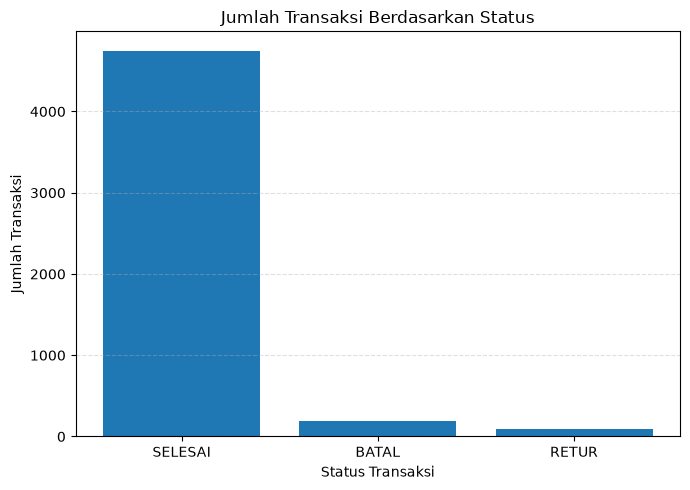

In [16]:
#grafik jumlah transaksi berdasarkan status
jumlah_status = df["status"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    jumlah_status.index,
    jumlah_status.values
)

plt.title("Jumlah Transaksi Berdasarkan Status")
plt.xlabel("Status Transaksi")
plt.ylabel("Jumlah Transaksi")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

grafik ini membandingkan jumlah transaksi SELESAI, BATAL, dan RETUR sebelum penyaringan pendapatan. grafik tersebut berguna untuk menunjukkan mengapa tidak semua transaksi boleh langsung dihitung sebagai pendapatan penjualan

In [17]:
#menyimpan transaksi yang sudah dibersihkan
df_valid.to_csv(
    "transaksi_bersih.csv",
    index=False
)

#menyimpan tabel pendapatan tahunan
pendapatan_tahunan.to_csv(
    "pendapatan_tahunan.csv",
    index=False
)

#menyimpan pendapatan bulanan
pendapatan_bulanan.to_csv(
    "pendapatan_bulanan.csv",
    index=False
)

print("semua file hasil analisis berhasil disimpan.")

semua file hasil analisis berhasil disimpan.


In [18]:
#RINGKASAN

print("RINGKASAN ANALISIS PENJUALAN")
print("=" * 35)

print("total transaksi awal:", len(df))
print("transaksi selesai yang dianalisis:", len(df_valid))
print("jumlah transaksi batal:", (df["status"].str.upper() == "BATAL").sum())
print("jumlah transaksi retur:", (df["status"].str.upper() == "RETUR").sum())

print(f"pendapatan bersih 2024: Rp{pendapatan_2024:,.2f}")
print(f"pendapatan bersih 2025: Rp{pendapatan_2025:,.2f}")

if pendapatan_2025 > pendapatan_2024:
    print("kesimpulan: pendapatan 2025 lebih tinggi daripada 2024.")
elif pendapatan_2025 < pendapatan_2024:
    print("kesimpulan: pendapatan 2025 lebih rendah daripada 2024.")
else:
    print("kesimpulan: pendapatan kedua tahun sama.")

RINGKASAN ANALISIS PENJUALAN
total transaksi awal: 5030
transaksi selesai yang dianalisis: 4712
jumlah transaksi batal: 191
jumlah transaksi retur: 90
pendapatan bersih 2024: Rp387,847,925.00
pendapatan bersih 2025: Rp259,271,725.00
kesimpulan: pendapatan 2025 lebih rendah daripada 2024.


## Kesimpulan

Berdasarkan analisis yang sudah dilakukan, dapat disimpulkan bahwa Python melalui Anaconda dapat membantu dalam mengolah dan menganalisis data penjualan dengan lebih mudah. Prosesnya dimulai dari membaca dataset, memeriksa data kosong (missing value), membersihkan data, hingga menghitung pendapatan dari setiap transaksi.

Dalam analisis ini, perhitungan pendapatan juga memperhatikan status transaksi dan diskon yang diberikan. Jadi, pendapatan yang dihitung hanya berasal dari transaksi yang sudah selesai dan sudah dikurangi diskon.

Selain itu, hasil analisis ditampilkan dalam bentuk tabel dan grafik agar lebih mudah dipahami, terutama untuk melihat perbandingan pendapatan tahun 2024 dan 2025 serta perubahan pendapatan setiap bulannya.